In [2]:
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from PIL import Image

In [3]:
# Detectar el dispositivo (CPU o GPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Instanciar ResNet18 y modificar la última capa para 10 clases (CIFAR-10)
model = models.resnet18(weights=None) # 'Weights=None' ya que cargaremos nuestros propios pesos entrenados
model.fc = nn.Linear(model.fc.in_features, 10)
model = model.to(device)

print(f"Modelo ResNet18 configurado para usar: {device}")

Modelo ResNet18 configurado para usar: cuda


In [4]:
# Obtengo las 10 clases del dataset CIFAR10
classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

In [5]:
# Cargar el archivo de los pesos guardados de ResNet
path_model = "cifar_net_resnet.pth"  # O el nombre con el que hayas guardado tu modelo de ResNet

try:
    model.load_state_dict(torch.load(path_model, map_location=device))
    model.eval()  # Configuramos el modelo en modo de evaluación
    print("¡Pesos de ResNet18 cargados correctamente con éxito!")
except FileNotFoundError:
    print(f"Error: No se encontró el archivo '{path_model}' en el directorio actual.")

¡Pesos de ResNet18 cargados correctamente con éxito!


In [6]:
# Definimos la misma normalización y tamaño (224x224) que usamos al entrenar ResNet
transform_inferencia = transforms.Compose([
    transforms.Resize((224, 224)),  # ResNet requiere 224x224
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],  # Media estándar de ImageNet
        std=[0.229, 0.224, 0.225]    # Desviación estándar de ImageNet
    )
])

def predecir_imagen(ruta_imagen):
    # Abrir la imagen original
    img_original = Image.open(ruta_imagen).convert('RGB')
    
    # Aplicar transformaciones para el modelo
    img_tensor = transform_inferencia(img_original).unsqueeze(0).to(device)
    
    # Realizar predicción sin calcular gradientes
    with torch.no_grad():
        output = model(img_tensor)
        _, preds_tensor = torch.max(output, 1)
        prediccion = classes[preds_tensor.item()]

    # Generar la visualización solicitada
    fig, ax = plt.subplots(figsize=(6, 6))
    
    # Mostrar la imagen original con la etiqueta de predicción
    ax.imshow(img_original)
    ax.set_title(f"Predicción (ResNet18): {prediccion.upper()}", fontsize=14, color='darkblue', weight='bold')
    ax.axis('off')
    
    plt.tight_layout()
    plt.show()

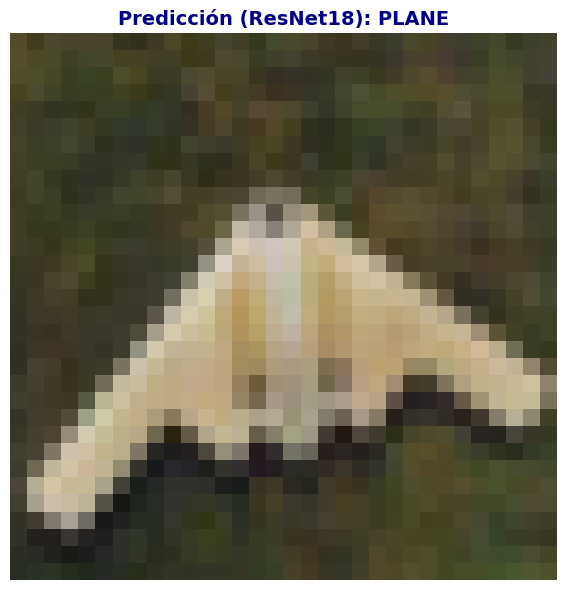

In [7]:
# Coloca aquí la ruta de la imagen que deseas probar
ruta_de_tu_imagen = "0006.png" 
#ruta_de_tu_imagen = "10_ieee.png"

# Llamamos a la función
predecir_imagen(ruta_de_tu_imagen)